In [301]:
# 그래프관련 import 
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

# 프로그램 
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier # 분류 클래스
from sklearn.neighbors import KNeighborsRegressor # 예측 클래스
from sklearn.linear_model import LinearRegression # 예측 클래스
from sklearn.metrics import mean_absolute_error # 평균절대오차 오차범위 클래스
from sklearn.preprocessing import StandardScaler  # 정규화 클래스
from sklearn.model_selection import train_test_split

In [302]:
perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0,
     21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5,
     22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5,
     27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0,
     36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0,
     40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
     )
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
     110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
     130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
     197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
     514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
     820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
     1000.0, 1000.0]
     )

In [303]:
# 1차원 배열들을 마치 세로 열(Column)처럼 옆으로 하나씩 붙여서 2차원 배열로 만들어주는 함수
data = np.column_stack((perch_length,perch_weight))
data[:2]

array([[ 8.4,  5.9],
       [13.7, 32. ]])

In [304]:
train_data, test_data, train_label, test_label = train_test_split(perch_length,perch_weight)
test_data

array([ 8.4, 22. , 20. , 37. , 40. , 24. , 22. , 24.6, 18. , 40. , 28. ,
       27.5, 34.5, 36.5])

In [305]:
train_data = train_data.reshape(-1,1)
test_data = test_data.reshape(-1,1)
train_data
test_data

array([[ 8.4],
       [22. ],
       [20. ],
       [37. ],
       [40. ],
       [24. ],
       [22. ],
       [24.6],
       [18. ],
       [40. ],
       [28. ],
       [27.5],
       [34.5],
       [36.5]])

In [306]:
train_poly = np.column_stack((train_data**2,train_data))
train_poly[:2]
test_poly = np.column_stack((test_data**2,test_data))
test_poly[:2]

array([[ 70.56,   8.4 ],
       [484.  ,  22.  ]])

In [307]:
lr = LinearRegression()
lr.fit(train_poly,train_label)

predict = lr.predict(train_poly)
print('예측 무게 : ', predict)

score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
print('train 정확도 :', score)
print('test 정확도 :', score2)


예측 무게 :  [ 136.95525532  160.92359241  806.77190738   87.30189395  382.7162006
  136.95525532  121.32522214 1077.39557505  982.84725514 1109.87622183
  292.6534781   285.96931198 1045.39719833  114.91599853  173.63116607
  599.01190131 1045.39719833   76.62472588  232.26936468  186.82100981
   12.47091184  148.69828883  292.6534781   699.03374374  806.77190738
  863.53460966  153.53053785  260.00427963  114.91599853  497.90022566
  136.95525532  863.53460966  114.91599853   51.54745903  334.37890226
  806.77190738  214.64750751   71.54656768  148.69828883   23.19114423
   35.98036381  648.05828237]
train 정확도 : 0.9715907974642932
test 정확도 : 0.9752456853353929


In [308]:
print(lr.coef_,lr.intercept_)

[  0.96454015 -19.43596978] 97.70915652777148


In [309]:
print(lr.coef_[0])

0.9645401526055866


In [310]:
point = np.arange(15,50)
print(point)

[15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38
 39 40 41 42 43 44 45 46 47 48 49]


In [311]:
# 25 입력받아 산점도 그래프에 표시하고 곡선도 출력하시오 
# in_data = 25
# result = lr.predict([[in_data**2,in_data]])
# print("예측 무게 : ", result)

in_data = 1000
result = lr.predict([[in_data**2,in_data]])
print("예측 무게 : ", result)

예측 무게 :  [945201.89198624]


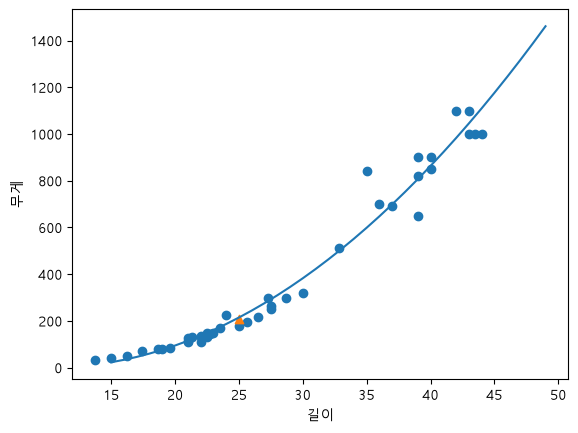

In [312]:
plt.scatter(train_data,train_label)
plt.scatter(25,208.14, marker='^')
plt.plot(point,lr.coef_[0]*point**2+lr.coef_[1]*point+lr.intercept_)
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()

In [313]:
bream_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0, 32.0, 32.0, 33.0, 33.0, 33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0]
bream_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0, 600.0, 600.0, 700.0, 700.0, 610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0]

# 빙어 - 14 
smelt_length = [9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
smelt_weight = [6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]

In [314]:
total_length = bream_length + smelt_length
total_weight = bream_weight + smelt_weight  

In [315]:
label = [1]*35 + [0]*14
# label = ['도미']*35 + ['빙어']*14

data = np.column_stack((total_length, total_weight))

In [316]:
train_data, test_data, train_label, test_label = train_test_split(data, label)

In [317]:
lr = LinearRegression()
lr.fit(train_data,train_label)

predict = lr.predict(test_data)
print('무게 예측 :', predict)

score = lr.score(train_data,train_label)
score2 = lr.score(test_data,test_label)
print('무게 예측 :', score)
print('무게 예측 :', score)

무게 예측 : [ 0.04039061  0.97140493  1.01489101  0.06672041  0.94245744  0.84689968
  1.12700162  1.05240072 -0.07048317 -0.06238359  0.97154444  0.87957249
  0.86985194]
무게 예측 : 0.9325450900521095
무게 예측 : 0.9325450900521095


In [318]:
print(lr.coef_,lr.intercept_)

[ 0.07557747 -0.00108366] -0.8559191508906155


In [319]:
print(lr.coef_[0])

0.07557747254783684


In [320]:
point = np.arange(15,50)
print(point)

[15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38
 39 40 41 42 43 44 45 46 47 48 49]


In [321]:
in_data = 25
result = lr.predict([[in_data**2,in_data]])
print("예측 무게 : ", result)

예측 무게 :  [46.35290959]


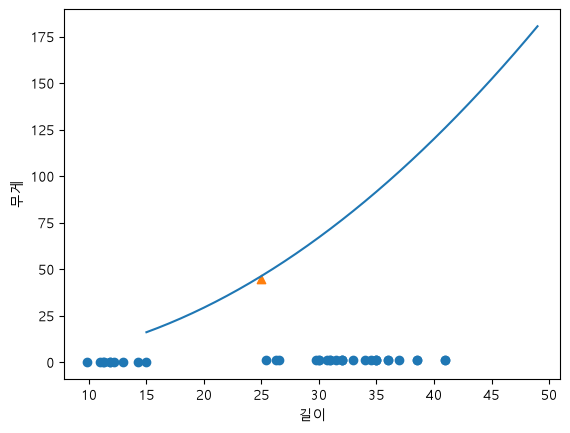

In [322]:
plt.scatter(train_data[:, 0], train_label)
plt.scatter(25, 44.685, marker='^')
plt.plot(point, lr.coef_[0]*point**2 + lr.coef_[1]*point + lr.intercept_)
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()